# COMP 4930SEF Project

**Group number:** 43

| Member | Full name | 8-digit student ID |
| --- | --- | --- |
| M1 | Chiang Sui Kit | 13492598 |
| M2 | Chen Hill Fung | 13492120 |
| M3 | Ip Ka Chung | 14108542 |

## Introduction

We will compare three classifiers on the CIFAR-100 animals-and-people subset, adapt the selected model to a dataset photographed and labelled by our group, and develop a text classifier for AG News. Each task will document the data, methodology, implementation, results and interpretation.

## Environment and shared utilities

The cell below records the Python, TensorFlow and Keras versions and the devices visible to TensorFlow.

In [1]:
import sys
from pathlib import Path

import tensorflow as tf

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "mise.toml").is_file():
    raise RuntimeError("Expected mise.toml in the current working directory.")

DATA_DIR = PROJECT_ROOT / "data"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts"
SEED = 42
tf.keras.utils.set_random_seed(SEED)

print(f"Python: {sys.version.split()[0]}")
print(f"TensorFlow: {tf.__version__}")
print(f"Keras: {tf.keras.__version__}")
print(f"GPUs: {tf.config.list_physical_devices('GPU')}")

I0000 00:00:1795337485.759008   39928 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795337485.791051   39928 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795337487.100129   39928 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Python: 3.12.15
TensorFlow: 2.21.0
Keras: 3.15.1
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Task 1 — CIFAR-100 animals and people

We compare ImageNet transfer at a common input resolution against a smaller CNN trained directly on CIFAR pixels. The shared validation split measures performance on unseen examples of the same 50 classes. It also lets us examine whether the extra parameters and training time of a pretrained network help on these small images.

In [2]:
import hashlib
import json
import os
from collections.abc import Iterator
from contextlib import contextmanager
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.model_selection import train_test_split

MODE = os.environ.get("TASK1_MODE", "preview").lower()
if MODE not in {"preview", "smoke", "train", "final"}:
    raise ValueError("TASK1_MODE must be preview, smoke, train, or final.")
BATCH_SIZE = int(os.environ.get("TASK1_BATCH_SIZE", "32"))
if BATCH_SIZE < 1:
    raise ValueError("TASK1_BATCH_SIZE must be at least 1.")
TASK1_DIR = Path("artifacts/task1")
RUN_SEEDS = (42, 43, 44)
gpus = tf.config.list_physical_devices("GPU")
if MODE in {"train", "final"} and not gpus:
    raise RuntimeError(
        "The full experiment needs the Legion GPU. See docs/task1-training.md."
    )

initial_policy = tf.keras.mixed_precision.global_policy().name
device_name = "CPU"
if MODE != "preview":
    if gpus:
        for gpu in gpus:
            if not tf.config.experimental.get_memory_growth(gpu):
                tf.config.experimental.set_memory_growth(gpu, True)
        with tf.device("/GPU:0"):
            probe = tf.linalg.matmul(tf.ones((2, 2)), tf.ones((2, 2)))
        if "GPU:0" not in probe.device or float(probe[0, 0]) != 2.0:
            raise RuntimeError("The GPU matrix multiplication check failed.")
        device_name = tf.config.experimental.get_device_details(gpus[0]).get(
            "device_name", "GPU"
        )
    tf.config.experimental.enable_op_determinism()
    tf.keras.mixed_precision.set_global_policy("mixed_float16" if gpus else "float32")
print(f"Task 1 mode = {MODE}, batch size = {BATCH_SIZE}")
if MODE != "preview":
    print(
        f"Device = {device_name}, precision = {tf.keras.mixed_precision.global_policy().name}"
    )

Task 1 mode = final, batch size = 32
Device = NVIDIA GeForce RTX 4070 Laptop GPU, precision = mixed_float16


I0000 00:00:1795337488.817698   39928 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5518 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4070 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


### Data and evaluation design

The appendix fixes the 50 fine-label IDs for this experiment. The table in code pairs those IDs with the names shipped with CIFAR-100. In particular, ID 57 is **pear**. We keep that class so the experiment uses the specified subset. Each example is a 32 × 32 RGB image. The split seed stays at 42 for all model seeds. Each class contributes 400 training images, 100 validation images and 100 images in the official test set. Only the selected model reaches the final test evaluation. [CIFAR-100 dataset](https://www.cs.toronto.edu/~kriz/cifar.html) · [Keras loader](https://keras.io/api/datasets/cifar100/) · [Fine-label names in source order](https://github.com/tensorflow/datasets/blob/master/tensorflow_datasets/testing/metadata/cifar100/3.0.2/label.labels.txt)

In [3]:
FINE_LABELS = {
    1: "aquarium_fish",
    2: "baby",
    3: "bear",
    4: "beaver",
    6: "bee",
    7: "beetle",
    11: "boy",
    14: "butterfly",
    15: "camel",
    18: "caterpillar",
    19: "cattle",
    21: "chimpanzee",
    24: "cockroach",
    26: "crab",
    27: "crocodile",
    29: "dinosaur",
    30: "dolphin",
    31: "elephant",
    32: "flatfish",
    34: "fox",
    35: "girl",
    36: "hamster",
    38: "kangaroo",
    42: "leopard",
    43: "lion",
    44: "lizard",
    45: "lobster",
    46: "man",
    50: "mouse",
    55: "otter",
    57: "pear",
    63: "porcupine",
    64: "possum",
    65: "rabbit",
    66: "raccoon",
    67: "ray",
    72: "seal",
    73: "shark",
    74: "shrew",
    75: "skunk",
    77: "snail",
    78: "snake",
    79: "spider",
    80: "squirrel",
    91: "trout",
    93: "turtle",
    95: "whale",
    97: "wolf",
    98: "woman",
    99: "worm",
}
FINE_IDS = tuple(FINE_LABELS)
CLASS_NAMES = tuple(FINE_LABELS.values())


def load_task1_data():
    """Return three native-resolution splits and a digest of the development row IDs."""
    (dev_x, dev_y), (test_x, test_y) = tf.keras.datasets.cifar100.load_data(
        label_mode="fine"
    )
    to_subset = np.full(100, -1, dtype=np.int32)
    to_subset[list(FINE_IDS)] = np.arange(len(FINE_IDS))
    dev_y = to_subset[dev_y.ravel()]
    test_y = to_subset[test_y.ravel()]
    dev_rows = np.flatnonzero(dev_y >= 0)
    test_rows = np.flatnonzero(test_y >= 0)
    fit_rows, val_rows = train_test_split(
        dev_rows, test_size=5_000, random_state=42, stratify=dev_y[dev_rows]
    )

    if np.intersect1d(fit_rows, val_rows).size:
        raise ValueError("Development partitions overlap.")
    train = (dev_x[fit_rows], dev_y[fit_rows])
    validation = (dev_x[val_rows], dev_y[val_rows])
    test = (test_x[test_rows], test_y[test_rows])
    for (images, labels), n in zip(
        (train, validation, test), (400, 100, 100), strict=True
    ):
        if (
            images.shape != (n * len(CLASS_NAMES), 32, 32, 3)
            or images.dtype != np.uint8
        ):
            raise ValueError(
                "Expected native 32 × 32 RGB images in channels-last order."
            )
        if not np.all(np.bincount(labels, minlength=len(CLASS_NAMES)) == n):
            raise ValueError(f"Expected {n} examples per fine class in this partition.")

    row_bytes = np.concatenate((fit_rows, val_rows)).astype("<i4").tobytes()
    return train, validation, test, hashlib.sha256(row_bytes).hexdigest()

### Reading model performance

Accuracy counts the images assigned the correct fine label. Top-5 accuracy also counts a correct label among the five highest scores. Macro-F1 gives every class the same weight and responds to both missed examples and incorrect assignments. The confusion matrix uses the true class on each row. A bright off-diagonal cell identifies a pair to inspect in the original images.

In [4]:
def classification_metrics(y_true: np.ndarray, scores: np.ndarray) -> dict[str, float]:
    """Compute the same three metrics from one inference pass on each checkpoint."""
    y_true = np.asarray(y_true).ravel()
    scores = np.asarray(scores)
    if scores.shape != (len(y_true), len(CLASS_NAMES)) or not np.isfinite(scores).all():
        raise ValueError("Expected one finite score per image and fine class.")
    ranked = np.argsort(-scores, axis=1, kind="stable")
    predicted = ranked[:, 0]
    return {
        "accuracy": float(np.mean(predicted == y_true)),
        "macro_f1": float(
            f1_score(
                y_true,
                predicted,
                labels=np.arange(len(CLASS_NAMES)),
                average="macro",
                zero_division=0,
            )
        ),
        "top5_accuracy": float(np.any(ranked[:, :5] == y_true[:, None], axis=1).mean()),
    }


def show_class_errors(y_true: np.ndarray, scores: np.ndarray, title: str) -> None:
    """Show per-class metrics, common directional errors and their full matrix."""
    y_true = np.asarray(y_true).ravel()
    predicted = np.argmax(scores, axis=1)
    labels = np.arange(len(CLASS_NAMES))
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true,
        predicted,
        labels=labels,
        zero_division=0,
    )
    per_class = pd.DataFrame(
        {
            "precision": precision,
            "recall": recall,
            "F1": f1,
            "support": support,
        },
        index=pd.Index(CLASS_NAMES, name="fine class"),
    )
    display(per_class.sort_values("F1").round(3))

    counts = confusion_matrix(y_true, predicted, labels=labels)
    errors = counts.copy()
    np.fill_diagonal(errors, 0)
    expected, assigned = np.nonzero(errors)
    pairs = pd.DataFrame(
        {
            "true": np.asarray(CLASS_NAMES)[expected],
            "predicted": np.asarray(CLASS_NAMES)[assigned],
            "images": errors[expected, assigned],
        }
    )
    display(pairs.nlargest(5, "images").reset_index(drop=True))

    fig, ax = plt.subplots(figsize=(11, 9), layout="constrained")
    fractions = np.divide(counts, np.maximum(counts.sum(axis=1, keepdims=True), 1))
    mesh = ax.imshow(fractions, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(labels, CLASS_NAMES, rotation=90, fontsize=7)
    ax.set_yticks(labels, CLASS_NAMES, fontsize=7)
    ax.set(xlabel="Predicted fine class", ylabel="True fine class", title=title)
    fig.colorbar(mesh, ax=ax, label="Fraction of each true class")
    plt.show()
    plt.close(fig)

### Three candidate models

| Candidate | Design | Question |
| --- | --- | --- |
| MobileNet V1 | ImageNet weights, depthwise and pointwise convolutions, 128 × 128 input | How well does a lightweight pretrained feature extractor transfer to these classes? |
| Custom CNN | Three blocks with 32, 64 and 128 channels, two 3 × 3 convolutions per block and 2 × 2 pooling after the first two | How much can a small model learn directly from the original 32 × 32 pixels? |
| EfficientNetV2B0 | ImageNet weights, fused and standard mobile inverted bottleneck blocks, 128 × 128 input | Does this alternative pretrained backbone improve recognition enough to justify its training cost? |

Each network averages the final feature map over its spatial dimensions, applies dropout at 0.25 and returns 50 float32 logits. The layer named `representation` exposes the pooled features for Task 2. Both transfer candidates resize each batch inside the model. MobileNet scales pixels to [−1, 1]. EfficientNetV2B0 applies its own preprocessing to pixels in [0, 255]. The custom model scales pixels to [0, 1]. Training adds horizontal flips and small translations of up to 6% of each dimension. At evaluation, Keras passes each image through the same resize and scaling steps with augmentation disabled.

Architecture and preprocessing references include [MobileNet V1](https://arxiv.org/abs/1704.04861), [EfficientNetV2](https://proceedings.mlr.press/v139/tan21a.html), the [Keras MobileNet API](https://keras.io/api/applications/mobilenet/) and the [Keras EfficientNetV2 API](https://www.tensorflow.org/api_docs/python/tf/keras/applications/EfficientNetV2B0).

In [5]:
CANDIDATES = ("mobilenet_v1", "custom_cnn", "efficientnetv2b0")


def build_candidate(name: str, seed: int, *, weights: str | None = "imagenet"):
    """Build a 50-way classifier accepting batches of raw RGB images."""
    if name not in CANDIDATES:
        raise ValueError(f"Unknown candidate: {name}")
    layers = tf.keras.layers
    size = 32 if name == "custom_cnn" else 128
    inputs = layers.Input(shape=(None, None, 3), dtype="uint8", name="rgb")
    x = layers.Resizing(size, size, dtype="float32", name="resize")(inputs)
    x = layers.RandomFlip("horizontal", seed=seed, dtype="float32")(x)
    x = layers.RandomTranslation(
        0.06, 0.06, fill_mode="reflect", seed=seed + 1, dtype="float32"
    )(x)
    if name == "custom_cnn":
        x = layers.Rescaling(1.0 / 255, dtype="float32")(x)
        for channels in (32, 64, 128):
            for _ in range(2):
                x = layers.Conv2D(channels, 3, padding="same", use_bias=False)(x)
                x = layers.BatchNormalization()(x)
                x = layers.Activation("relu")(x)
            if channels < 128:
                x = layers.MaxPooling2D()(x)
    else:
        if name == "mobilenet_v1":
            x = layers.Rescaling(1.0 / 127.5, offset=-1, dtype="float32")(x)
            backbone = tf.keras.applications.MobileNet(
                input_shape=(size, size, 3), include_top=False, weights=weights
            )
        else:
            backbone = tf.keras.applications.EfficientNetV2B0(
                input_shape=(size, size, 3),
                include_top=False,
                include_preprocessing=True,
                weights=weights,
            )
        backbone.trainable = False
        x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D(name="representation", dtype="float32")(x)
    x = layers.Dropout(0.25, seed=seed + 2)(x)
    logits = layers.Dense(50, name="classifier", dtype="float32")(x)
    return tf.keras.Model(inputs, logits, name=name)


def unfreeze_final_blocks(model) -> None:
    """Release the last convolutional blocks while freezing BatchNorm statistics."""
    backbone = next(
        layer for layer in model.layers if isinstance(layer, tf.keras.Model)
    )
    prefixes = (
        ("conv_dw_12", "conv_pw_12", "conv_dw_13", "conv_pw_13")
        if model.name == "mobilenet_v1"
        else ("block6", "top_conv")
    )
    backbone.trainable = True
    for layer in backbone.layers:
        layer.trainable = layer.name.startswith(prefixes) and not isinstance(
            layer, tf.keras.layers.BatchNormalization
        )
    if not backbone.trainable_weights:
        raise ValueError(f"No trainable layers matched {prefixes} in {backbone.name}.")

### Training and checkpoint selection

The custom CNN starts from random weights and receives up to 18 epochs with Adam at 0.001. Each transfer candidate trains its head for up to four epochs at 0.001. Starting from the best head weights, it then fine-tunes the last MobileNet blocks (12 and 13) or EfficientNet stage 6 and its top convolution for up to eight epochs at 0.00001. The smaller step size lets the upper features adapt gradually. Frozen BatchNorm layers use their saved statistics throughout transfer training. With the pinned Keras version, EfficientNetV2B0 also applies its built-in stochastic depth during fitting. This randomly skips some residual contributions as a regulariser. All dropout is disabled for validation and test predictions. Keras recompiles with a fresh optimizer after the trainable layers change. [Keras transfer learning guide](https://keras.io/guides/transfer_learning/)

Each stage stops after three consecutive epochs without higher validation accuracy. The saved model comes from the highest validation accuracy across all stages, retaining the earliest epoch on a tie. The comparison includes differences in pretraining, resolution and training budget. Recorded fit time includes checkpoint writes and excludes initial weight downloads.

In [6]:
def train_candidate(
    name: str,
    seed: int,
    train_ds,
    val_ds,
    run_dir: Path,
    *,
    weights: str | None = "imagenet",
    head_epochs: int,
    tune_epochs: int,
    scratch_epochs: int,
):
    """Train one seed and keep the highest validation accuracy across its stages."""
    policy = tf.keras.mixed_precision.global_policy().name
    tf.keras.backend.clear_session()
    tf.keras.mixed_precision.set_global_policy(policy)
    tf.keras.utils.set_random_seed(seed)
    model = build_candidate(name, seed, weights=weights)
    run_dir.mkdir(parents=True, exist_ok=True)
    checkpoint = run_dir / "best.keras"
    stages = (
        [("scratch", scratch_epochs, 1e-3)]
        if name == "custom_cnn"
        else [("head", head_epochs, 1e-3), ("fine_tune", tune_epochs, 1e-5)]
    )
    history: list[dict[str, str | float | int]] = []
    best_epoch = 0
    best_stage = ""
    best_accuracy = -np.inf
    start = perf_counter()
    for stage, epochs, learning_rate in stages:
        if epochs < 1:
            raise ValueError(f"The {stage} stage needs at least one epoch.")
        if stage == "fine_tune":
            unfreeze_final_blocks(model)
        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate),
            loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
            metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
            jit_compile=False,
        )
        save_best = tf.keras.callbacks.ModelCheckpoint(
            str(checkpoint),
            monitor="val_accuracy",
            mode="max",
            save_best_only=True,
            initial_value_threshold=best_accuracy,
        )
        early_stop = tf.keras.callbacks.EarlyStopping(
            monitor="val_accuracy", mode="max", patience=3, restore_best_weights=True
        )
        print(f"{name} | seed {seed} | {stage} | learning rate {learning_rate:g}")
        fit = model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=epochs,
            callbacks=[save_best, early_stop],
            shuffle=False,
            verbose=2,
        )
        for i in range(len(fit.epoch)):
            metrics = {
                key: float(fit.history[key][i])
                for key in ("loss", "accuracy", "val_loss", "val_accuracy")
            }
            if not all(np.isfinite(value) for value in metrics.values()):
                raise ValueError(f"Non-finite training metrics in {name}, seed {seed}.")
            history.append({"stage": stage, "epoch": len(history) + 1, **metrics})
            if metrics["val_accuracy"] > best_accuracy:
                best_accuracy = metrics["val_accuracy"]
                best_epoch = len(history)
                best_stage = stage

    return {
        "checkpoint": str(checkpoint),
        "history": history,
        "parameters": model.count_params(),
        "seconds": perf_counter() - start,
        "best_epoch": best_epoch,
        "best_stage": best_stage,
        "best_val_accuracy": best_accuracy,
    }

### Training and validation

Each seed starts with fresh weights and a freshly shuffled training stream. Validation images keep a fixed order. For each run we reload the checkpoint with the highest validation accuracy and calculate every validation metric from the same predictions. Resetting the seed before dataset construction fixes the shuffle stream even when earlier runs are loaded from disk. A completed run can be reused after restarting the kernel. The experiment directory records the split, software versions, precision, batch size and the code used to train it.

In [7]:
@contextmanager
def task1_writer() -> Iterator[None]:
    """Hold an OS file lock while one kernel writes run or final artifacts."""
    TASK1_DIR.mkdir(parents=True, exist_ok=True)
    with (TASK1_DIR / ".writer.lock").open("a+b") as handle:
        handle.seek(0)
        try:
            if sys.platform == "win32":
                import msvcrt

                msvcrt.locking(handle.fileno(), msvcrt.LK_NBLCK, 1)
            else:
                import fcntl

                fcntl.flock(handle, fcntl.LOCK_EX | fcntl.LOCK_NB)
        except OSError as exc:
            raise RuntimeError(
                f"Could not lock {TASK1_DIR}. Check for another active kernel."
            ) from exc
        yield  # Closing the handle releases the lock, including on kernel exit.


def make_batches(pair, batch_size: int, seed: int | None = None):
    images, labels = pair
    batches = tf.data.Dataset.from_tensor_slices((images, labels))
    if seed is not None:
        batches = batches.shuffle(len(labels), seed=seed, reshuffle_each_iteration=True)
    return batches.batch(batch_size).prefetch(tf.data.AUTOTUNE)


def smoke_sample(pair, per_class: int):
    images, labels = pair
    indices = np.concatenate(
        [np.flatnonzero(labels == i)[:per_class] for i in range(len(CLASS_NAMES))]
    )
    return images[indices], labels[indices]


def file_digest(path: Path) -> str:
    with path.open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()


def write_json(path: Path, record: dict) -> None:
    temporary = path.with_suffix(".tmp")
    temporary.write_text(
        json.dumps(record, indent=2, allow_nan=False), encoding="utf-8"
    )
    temporary.replace(path)


def experiment_settings(split_id: str) -> dict:
    """Identify reusable runs from the saved notebook's training cells and data."""
    report = json.loads(Path("project_report.ipynb").read_text(encoding="utf-8"))
    sources = [
        "".join(cell["source"])
        for cell in report["cells"]
        if "task1-protocol" in cell["metadata"].get("tags", [])
    ]
    return {
        "protocol_sha256": hashlib.sha256("\n".join(sources).encode()).hexdigest(),
        "split_sha256": split_id,
        "smoke": MODE == "smoke",
        "batch_size": BATCH_SIZE,
        "tensorflow": tf.__version__,
        "keras": tf.keras.__version__,
        "device": device_name,
        "precision": tf.keras.mixed_precision.global_policy().name,
        "fine_ids": list(FINE_IDS),
        "classes": list(CLASS_NAMES),
    }


def validation_run(name: str, seed: int, fit_pair, val_pair, directory: Path) -> dict:
    """Finish one fit, or read its completed checkpoint and validation predictions."""
    run_dir = directory / name / str(seed)
    run_dir.mkdir(parents=True, exist_ok=True)
    record_file = run_dir / "run.json"
    checkpoint = run_dir / "best.keras"
    predictions = run_dir / "validation.npy"
    if record_file.is_file():
        record = json.loads(record_file.read_text(encoding="utf-8"))
        if (
            file_digest(checkpoint) != record["checkpoint_sha256"]
            or file_digest(predictions) != record["validation_sha256"]
        ):
            raise ValueError(f"Saved run files do not match {record_file}.")
        print(f"Loaded {name}, seed {seed}")
        return record
    if MODE == "final":
        raise RuntimeError(
            f"Missing completed validation run {name}, seed {seed}. Run train first."
        )
    head, tune, scratch = (1, 1, 1) if MODE == "smoke" else (4, 8, 18)
    tf.keras.utils.set_random_seed(seed)
    record = train_candidate(
        name,
        seed,
        make_batches(fit_pair, BATCH_SIZE, seed),
        make_batches(val_pair, BATCH_SIZE),
        run_dir,
        head_epochs=head,
        tune_epochs=tune,
        scratch_epochs=scratch,
    )
    best_model = tf.keras.models.load_model(checkpoint, compile=False)
    scores = best_model.predict(val_pair[0], batch_size=BATCH_SIZE, verbose=0)
    metrics = classification_metrics(val_pair[1], scores)
    if not np.isclose(metrics["accuracy"], record["best_val_accuracy"], atol=1e-5):
        print(
            f"Reloaded accuracy {metrics['accuracy']:.4f}, "
            f"recorded at fit {record['best_val_accuracy']:.4f}. Check close logits."
        )
    np.save(predictions, scores)
    record.update(
        metrics,
        candidate=name,
        seed=seed,
        checkpoint_sha256=file_digest(checkpoint),
        validation_sha256=file_digest(predictions),
    )
    write_json(record_file, record)
    return record

In [8]:
if MODE != "preview":
    fit_pair, val_pair, official_test_pair, split_id = load_task1_data()
    print(
        f"Official subset: {len(fit_pair[1]):,} fit, {len(val_pair[1]):,} validation, "
        f"{len(official_test_pair[1]):,} test. Split SHA-256: {split_id}"
    )
    settings = experiment_settings(split_id)
    experiment_id = hashlib.sha256(
        json.dumps(settings, sort_keys=True).encode()
    ).hexdigest()[:20]
    directory = (
        TASK1_DIR / ("smoke" if MODE == "smoke" else "experiments") / experiment_id
    )
    directory.mkdir(parents=True, exist_ok=True)
    if MODE == "smoke":
        fit_pair, val_pair = smoke_sample(fit_pair, 2), smoke_sample(val_pair, 1)
        print("Pipeline check only: 100 training and 50 validation images.")
    with task1_writer():
        write_json(directory / "settings.json", settings)
        records = [
            validation_run(name, seed, fit_pair, val_pair, directory)
            for name in CANDIDATES
            for seed in ((42,) if MODE == "smoke" else RUN_SEEDS)
        ]
    run_table = pd.DataFrame(records)
    display(
        run_table[
            [
                "candidate",
                "seed",
                "best_stage",
                "best_epoch",
                "accuracy",
                "macro_f1",
                "top5_accuracy",
                "parameters",
                "seconds",
            ]
        ].round(4)
    )

Official subset: 20,000 fit, 5,000 validation, 5,000 test. Split SHA-256: cef94046a3e1a70ae28edde35213447fbaedd9ee6e5da8f391f96a41bf32ee64
Loaded mobilenet_v1, seed 42
Loaded mobilenet_v1, seed 43
Loaded mobilenet_v1, seed 44
Loaded custom_cnn, seed 42
Loaded custom_cnn, seed 43
Loaded custom_cnn, seed 44
Loaded efficientnetv2b0, seed 42
Loaded efficientnetv2b0, seed 43
Loaded efficientnetv2b0, seed 44


,candidate,seed,best_stage,best_epoch,accuracy,macro_f1,top5_accuracy,parameters,seconds
0,mobilenet_v1,42,fine_tune,12,0.6564,0.6557,0.9040,3280114,144.8273
1,mobilenet_v1,43,fine_tune,11,0.6576,0.6546,0.9032,3280114,131.0274
2,mobilenet_v1,44,fine_tune,12,0.6528,0.6486,0.9038,3280114,130.6565
3,custom_cnn,42,scratch,10,0.3510,0.3478,0.6812,294802,245.2219
4,custom_cnn,43,scratch,6,0.3424,0.3165,0.6758,294802,107.6459
5,custom_cnn,44,scratch,10,0.3876,0.3702,0.7340,294802,246.8071
6,efficientnetv2b0,42,fine_tune,12,0.7584,0.7573,0.9514,5983362,361.0000
7,efficientnetv2b0,43,fine_tune,12,0.7576,0.7561,0.9526,5983362,291.7466
8,efficientnetv2b0,44,fine_tune,12,0.7628,0.7614,0.9510,5983362,360.6347


### Validation results

The table reports the mean and sample standard deviation of validation accuracy across the three training seeds. The curves and confusion matrices show seed 42 on the same 5,000 validation images. Each dotted line marks the epoch saved for that model.

,mean_accuracy,sd_accuracy,mean_macro_f1,mean_top5,parameters,mean_seconds
candidate,,,,,,
efficientnetv2b0,0.7596,0.0028,0.7583,0.9517,5983362,337.7938
mobilenet_v1,0.6556,0.0025,0.6530,0.9037,3280114,135.5037
custom_cnn,0.3603,0.0240,0.3448,0.6970,294802,199.8916


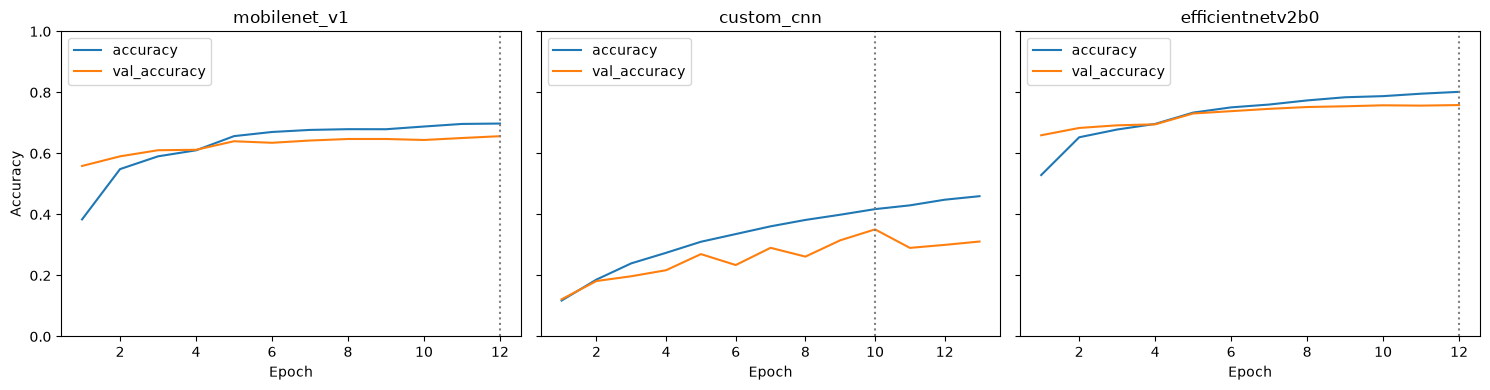

,precision,recall,F1,support
fine class,,,,
otter,0.381,0.37,0.376,100
girl,0.542,0.32,0.403,100
seal,0.414,0.41,0.412,100
boy,0.447,0.42,0.433,100
man,0.462,0.43,0.446,100
woman,0.408,0.58,0.479,100
shrew,0.464,0.52,0.491,100
mouse,0.564,0.44,0.494,100
baby,0.564,0.44,0.494,100


,true,predicted,images
0,girl,woman,26
1,man,woman,17
2,boy,woman,16
3,baby,boy,15
4,shark,dolphin,14


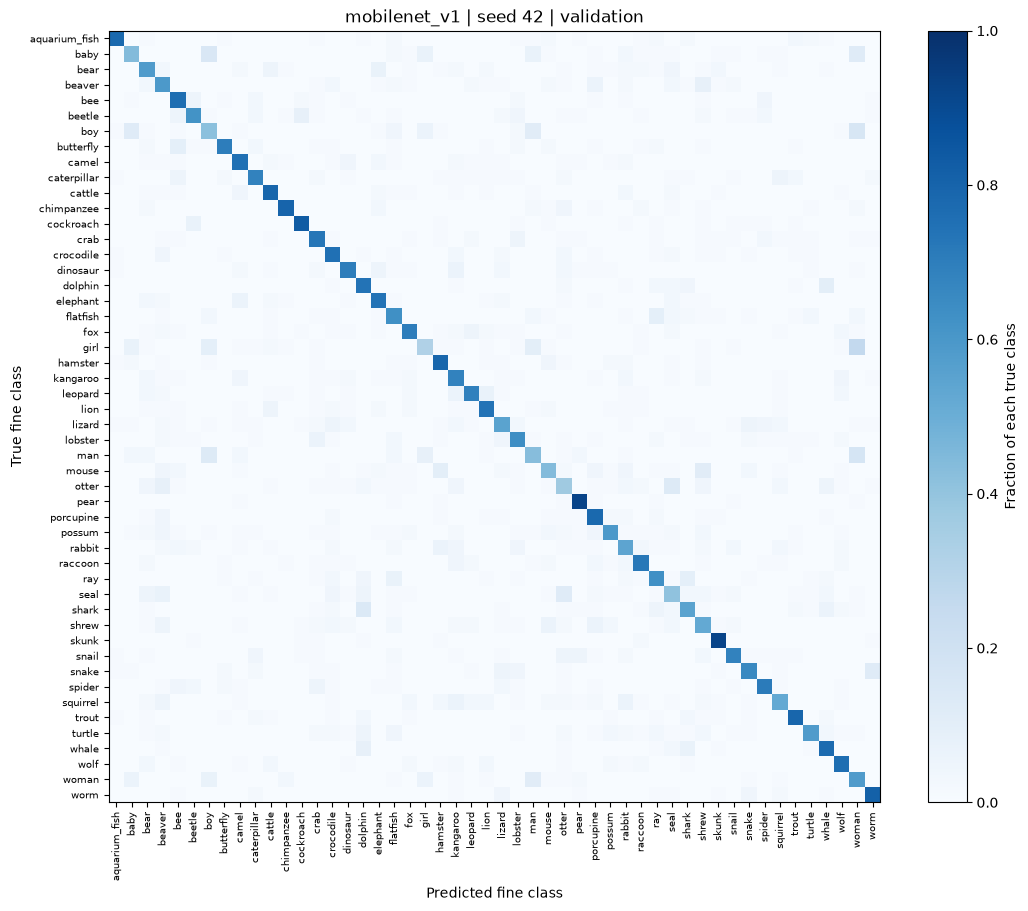

,precision,recall,F1,support
fine class,,,,
squirrel,0.312,0.05,0.086,100
girl,0.625,0.05,0.093,100
seal,0.231,0.06,0.095,100
otter,0.240,0.06,0.096,100
mouse,0.240,0.06,0.096,100
snake,0.818,0.09,0.162,100
beaver,0.162,0.18,0.171,100
rabbit,0.167,0.18,0.173,100
lizard,0.550,0.11,0.183,100


,true,predicted,images
0,camel,cattle,37
1,elephant,cattle,36
2,porcupine,leopard,35
3,snake,leopard,32
4,boy,man,30


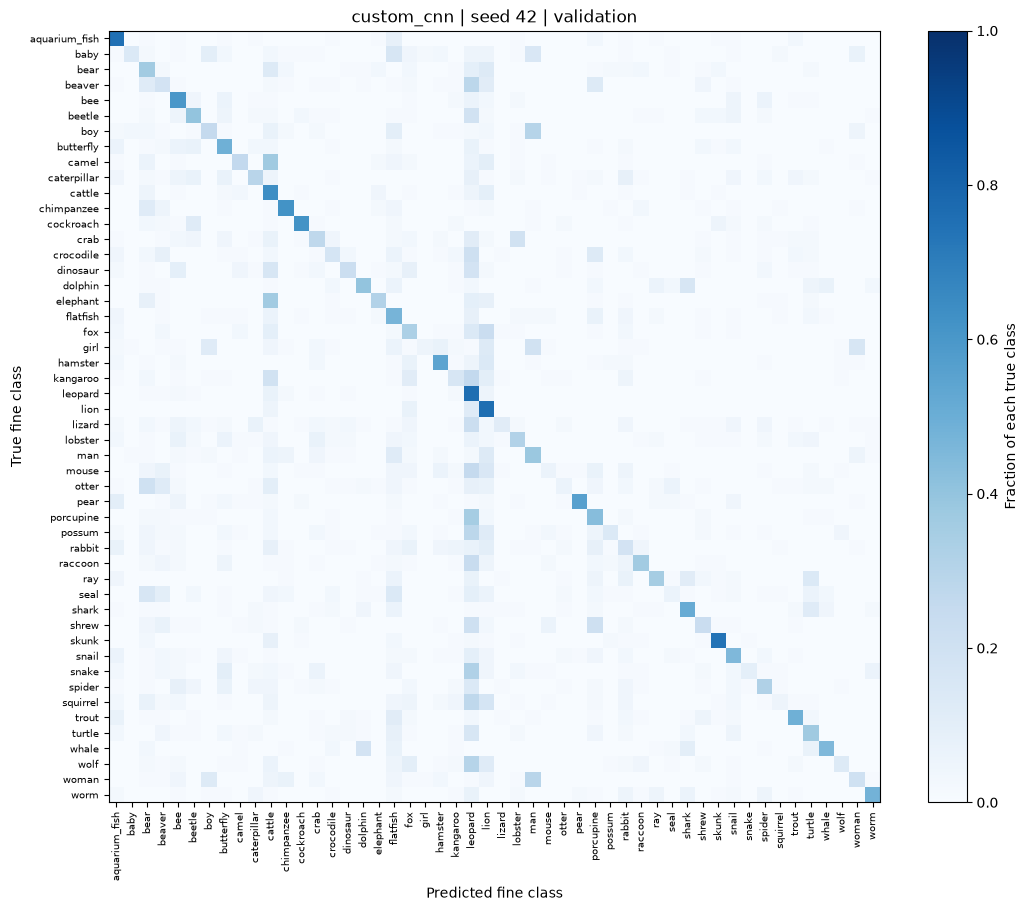

,precision,recall,F1,support
fine class,,,,
girl,0.553,0.47,0.508,100
boy,0.580,0.51,0.543,100
seal,0.560,0.56,0.560,100
shrew,0.650,0.52,0.578,100
otter,0.602,0.56,0.580,100
mouse,0.637,0.58,0.607,100
woman,0.575,0.65,0.610,100
baby,0.667,0.60,0.632,100
shark,0.618,0.68,0.648,100


,true,predicted,images
0,girl,woman,21
1,boy,man,16
2,baby,girl,15
3,baby,boy,12
4,boy,baby,12


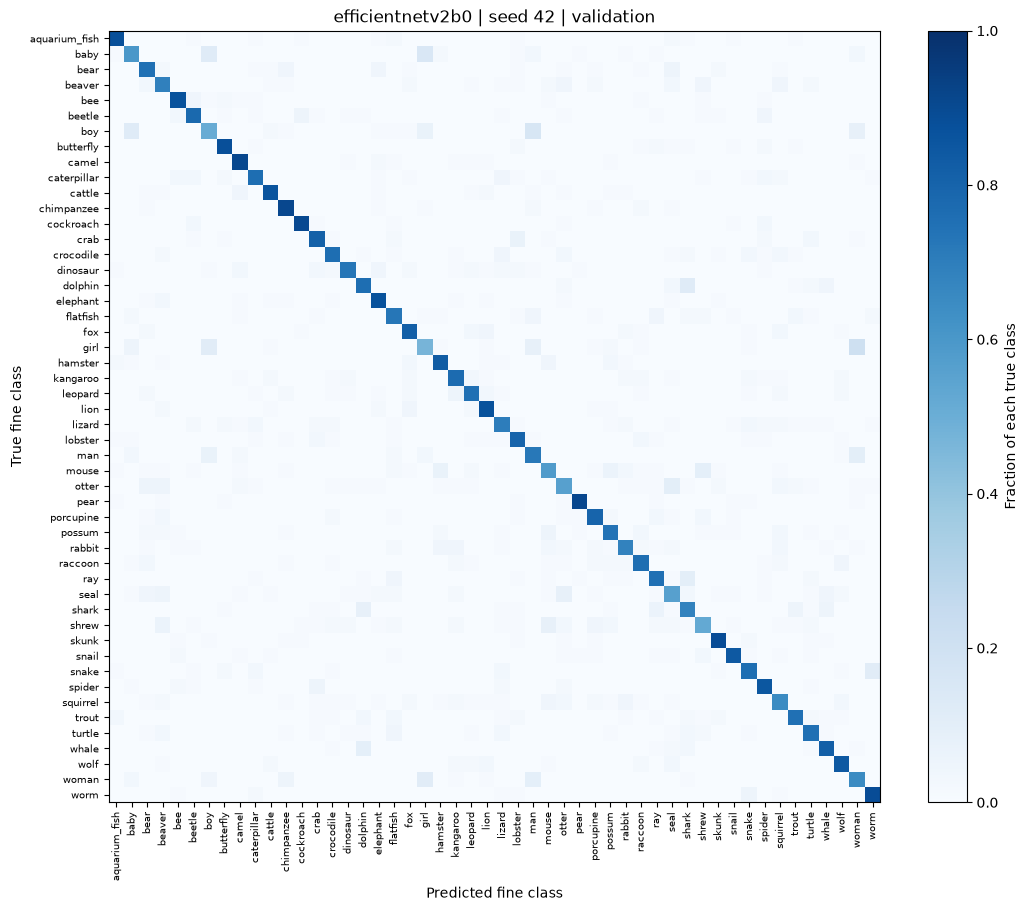

In [9]:
def rank_candidates(table: pd.DataFrame) -> pd.DataFrame:
    expected = {(name, seed) for name in CANDIDATES for seed in RUN_SEEDS}
    # Nine rows can still hide a missing seed. Duplicates are sneaky like that.
    received = set(zip(table["candidate"], table["seed"], strict=True))
    if received != expected or len(table) != len(expected):
        raise ValueError("Recommendation requires all nine candidate/seed results.")
    ranking = table.groupby("candidate").agg(
        mean_accuracy=("accuracy", "mean"),
        sd_accuracy=("accuracy", "std"),
        mean_macro_f1=("macro_f1", "mean"),
        mean_top5=("top5_accuracy", "mean"),
        parameters=("parameters", "first"),
        mean_seconds=("seconds", "mean"),
    )
    return ranking.sort_values(
        ["mean_accuracy", "mean_macro_f1", "parameters"], ascending=[False, False, True]
    )


if MODE in {"train", "final"}:
    ranking = rank_candidates(run_table)
    display(ranking.round(4))
    fig, axes = plt.subplots(1, len(CANDIDATES), figsize=(15, 4), sharey=True)
    for ax, name in zip(axes, CANDIDATES, strict=True):
        run = next(r for r in records if r["candidate"] == name and r["seed"] == 42)
        curve = pd.DataFrame(run["history"]).set_index("epoch")
        curve[["accuracy", "val_accuracy"]].plot(ax=ax)
        ax.axvline(run["best_epoch"], color="grey", linestyle=":")
        ax.set(title=name, xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1))
    fig.tight_layout()
    plt.show()
    for name in CANDIDATES:
        scores = np.load(directory / name / "42" / "validation.npy", allow_pickle=False)
        show_class_errors(val_pair[1], scores, f"{name} | seed 42 | validation")

### What the three models learned

**MobileNet V1** averaged 65.56% validation accuracy and 0.6530 macro-F1. Its best checkpoint came during fine-tuning at every seed. For seed 42, validation accuracy rose from 61.18% at the end of head training to 65.64% at epoch 12. At 136 seconds per run on average, it was the fastest candidate.

**The custom CNN** used just 294,802 parameters. Its validation accuracy ranged from 34.24% to 38.76%, and its mean macro-F1 was 0.3448. The seed-42 curve explains why we kept the epoch-10 checkpoint. Training accuracy continued to rise over the next three epochs while validation accuracy stayed below its 35.10% peak. The confusion matrix shows one recurring error. The model labelled 37 of 100 camels and 36 of 100 elephants as cattle. A useful follow-up would compare a lower learning rate on the same validation split to see whether the scratch model trains more consistently across seeds.

**EfficientNetV2B0** had the strongest head-only result at seed 42, reaching 69.52% after four epochs. Fine-tuning raised it another 6.32 percentage points to 75.84%. Its mean fit time was 338 seconds, about 2.5 times MobileNet's. Both transfer models used ImageNet weights and 128 × 128 inputs. The custom CNN learned from scratch at 32 × 32, so its comparison with the transfer models measures the combined effect of those design choices.

## Recommendation and final evaluation

We recommend **EfficientNetV2B0**. Its mean validation accuracy was **75.96%**, ahead of MobileNet V1 by **10.40 percentage points**. It led at all three seeds, with a standard deviation of 0.28 percentage points. Its mean macro-F1 of 0.7583 also led the comparison. For this task, that consistent accuracy gain justifies the longer training time.

We selected the **seed-42 checkpoint at epoch 12**, the last fine-tuning epoch. Seed 44 achieved 76.28% validation accuracy, but our selection rule fixed seed 42 before training. We evaluated the selected checkpoint on the 5,000 official test images after completing the validation comparison.

In [10]:
if MODE in {"train", "final"}:
    winner = str(ranking.index[0])
    # Seed 44 looks tempting in the table. We agreed on 42 before training.
    selected = next(r for r in records if r["candidate"] == winner and r["seed"] == 42)
    margin = ranking.mean_accuracy.iloc[0] - ranking.mean_accuracy.iloc[1]
    print(
        f"Recommend {winner}: mean validation accuracy {ranking.mean_accuracy.iloc[0]:.2%}, "
        f"{100 * margin:.2f} percentage points above the runner-up."
    )
    print(f"Selected checkpoint: {selected['checkpoint']}")

Recommend efficientnetv2b0: mean validation accuracy 75.96%, 10.40 percentage points above the runner-up.
Selected checkpoint: artifacts/task1/experiments/bcfbdbfa0221d719e350/efficientnetv2b0/42/best.keras


E0000 00:00:1795337491.435955   39928 util.cc:131] oneDNN supports DT_HALF only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.
E0000 00:00:1795337493.029587   39928 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
I0000 00:00:1795337494.337482   40078 cuda_dnn.cc:461] Loaded cuDNN version 92801


,accuracy,macro_f1,top5_accuracy
efficientnetv2b0,0.7448,0.7439,0.9534


,precision,recall,F1,support
fine class,,,,
boy,0.592,0.45,0.511,100
girl,0.568,0.50,0.532,100
shrew,0.551,0.54,0.545,100
mouse,0.553,0.57,0.562,100
woman,0.547,0.58,0.563,100
otter,0.588,0.57,0.579,100
seal,0.566,0.64,0.601,100
man,0.588,0.67,0.626,100
squirrel,0.621,0.64,0.631,100


,true,predicted,images
0,boy,man,20
1,girl,woman,20
2,otter,seal,18
3,snake,worm,15
4,woman,man,14


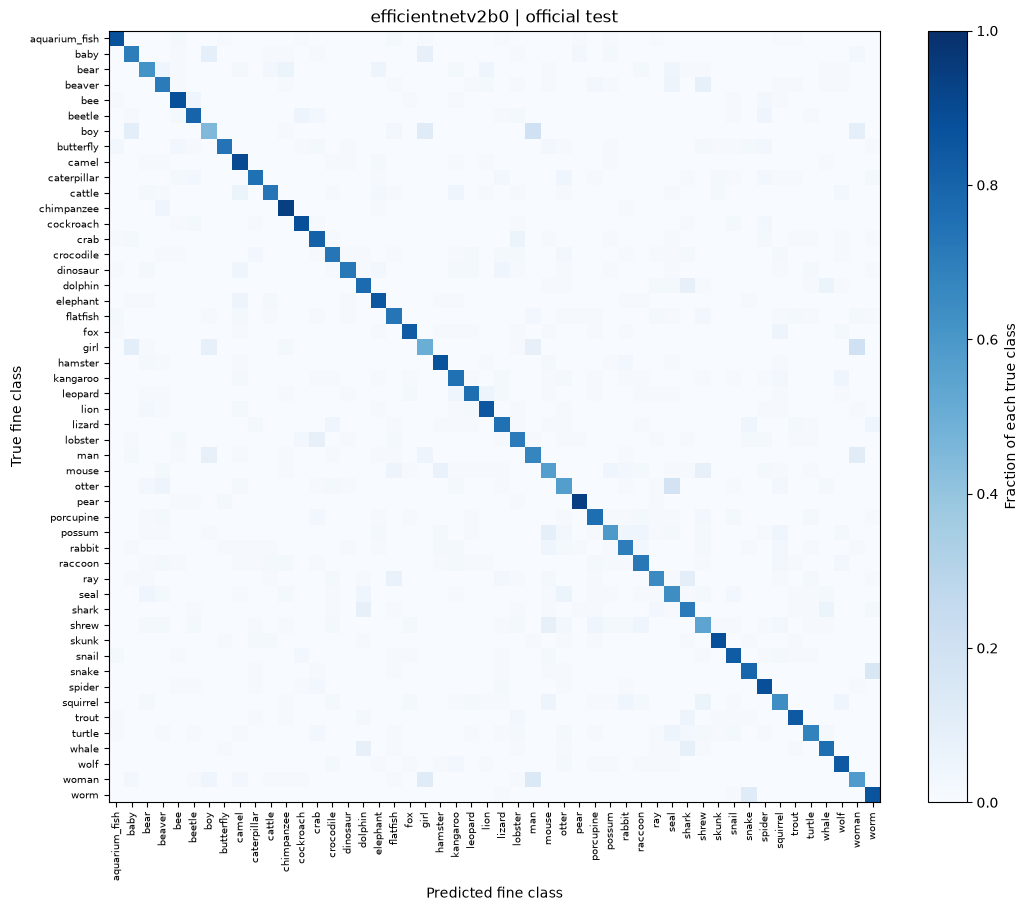

Task 2 checkpoint, feature layer and input contract: artifacts/task1/final/selection.json


In [11]:
def final_predictions(selection: dict, settings: dict, experiment_id: str, images):
    """Keep the official predictions tied to one selected checkpoint across reruns."""
    with task1_writer():
        final_dir = TASK1_DIR / "final"
        final_dir.mkdir(parents=True, exist_ok=True)
        manifest = final_dir / "selection.json"
        prediction_file = final_dir / "test_scores.npy"
        lock = {
            "experiment_id": experiment_id,
            "candidate": selection["candidate"],
            "seed": 42,
            "checkpoint": selection["checkpoint"],
            "checkpoint_sha256": selection["checkpoint_sha256"],
            "class_names": settings["classes"],
            "original_fine_ids": settings["fine_ids"],
            "input": "RGB 32x32, pixel values 0..255; preprocessing embedded in model",
            "feature_layer": "representation",
            "split_sha256": settings["split_sha256"],
        }
        if manifest.exists():
            if json.loads(manifest.read_text(encoding="utf-8")) != lock:
                raise ValueError(
                    "Official evaluation already belongs to a different selection."
                )
        elif prediction_file.exists():
            raise ValueError("Test predictions are missing their selection manifest.")
        else:
            write_json(manifest, lock)
        # The GPU already answered these 5,000 questions. Read its answers back.
        if prediction_file.exists():
            return np.load(prediction_file, allow_pickle=False)
        if file_digest(Path(lock["checkpoint"])) != lock["checkpoint_sha256"]:
            raise ValueError("Selected checkpoint changed since validation.")
        model = tf.keras.models.load_model(lock["checkpoint"], compile=False)
        scores = model.predict(images, batch_size=BATCH_SIZE, verbose=0)
        pending = final_dir / "test_scores.pending.npy"
        np.save(pending, scores)
        # Only give the file its final name once every score is on disk.
        pending.replace(prediction_file)
        return scores


if MODE == "final":
    test_scores = final_predictions(
        selected, settings, experiment_id, official_test_pair[0]
    )
    test_metrics = classification_metrics(official_test_pair[1], test_scores)
    display(pd.DataFrame([test_metrics], index=[winner]).round(4))
    show_class_errors(official_test_pair[1], test_scores, f"{winner} | official test")
    print(
        "Task 2 checkpoint, feature layer and input contract: artifacts/task1/final/selection.json"
    )

if MODE != "preview":
    tf.keras.mixed_precision.set_global_policy(initial_policy)

### Held-out performance and Task 2 handoff

EfficientNetV2B0 correctly classified **3,724 of 5,000** test images (**74.48% accuracy**, **0.7439 macro-F1**). Compared with the same checkpoint on validation, accuracy fell by **1.36 percentage points** and macro-F1 by 0.0134. Top-5 accuracy reached **95.34%**. Among the 1,276 top-1 errors, 1,043 still had the correct class in positions two through five.

The test set has 100 images per class. The model recognised 94 pears and 88 skunks, compared with 45 images labelled `boy` and 50 labelled `girl`. It predicted `man` for 20 of the `boy` images and `woman` for 20 of the `girl` images. It also assigned 18 of the 100 otters to `seal`. These errors suggest that fine visual distinctions are difficult at the original 32 × 32 resolution. Inspecting individual errors would help distinguish ambiguous views from cases with clear identifying features.

For Task 2 we will reuse the recorded seed-42 `best.keras` checkpoint and its pooled `representation` layer, then fit a five-class head for the containers. The test score measures recognition of the specified CIFAR classes. We will assess transfer to the team's photographs on held-out container designs.

## Task 2 — Group-collected image classification

### Collection and labelling

We have selected five container classes: `mug`, `paper_cup`, `plastic_bottle`, `aluminium_can`, and `drink_carton`, in the order recorded in `data/task2/classes.json`. Follow the [collection guide](docs/data-collection.md) for class boundaries and the shooting checklist.

Our collection target is 200 usable photographs per member, with approximately 40 per class. We will coordinate object designs in the shared register, photograph them across two sessions, and review the labels and capture records. Record actual counts, member contributions and exclusions after collection. Use the manifests to create a group-separated training/validation split, keeping shared objects and matching designs together.

### Adaptation and evaluation

Adapt the actual selected Task 1 checkpoint. Explain and evaluate the changes to its head, preprocessing, training stages and augmentation.

### Predictions and error analysis

Display 25 fixed validation examples with actual and predicted labels, then analyse class and condition-specific errors.

## Task 3 — AG News topic classification

Can a short news item be routed to **World, Sports, Business or Sci/Tech** from its headline and description? AG News gives us labelled examples of all four topics in equal numbers and a separate benchmark test set. Topic routing is a practical use of short-text classification. Articles about the business of technology also give us a meaningful class boundary to examine.

We compare two reading lengths for one word-level TextCNN. Convolutions can recognise short phrases such as *interest rates* and *World Cup* even when they occur in different positions. We train the word embeddings alongside the classifier. Both runs use the same articles, vocabulary, model settings and random seed. See the [AG News benchmark](https://arxiv.org/abs/1509.01626), [TFDS dataset entry](https://www.tensorflow.org/datasets/catalog/ag_news_subset) and [Kim's sentence CNN](https://aclanthology.org/D14-1181/).

### Load AG News

We load the pinned `ag_news_subset:1.0.0` version. TFDS supplies the title, description and topic ID (0–3). Its supervised shortcut supplies only the description, so we request complete records. Before model selection we use official test **text** solely to exclude matching development articles. Test labels enter the final evaluation after selection.

In [1]:
import hashlib
import html
import json
import os
import platform
import re
import time
import unicodedata
from collections import defaultdict
from collections.abc import Mapping
from pathlib import Path
from tempfile import NamedTemporaryFile, TemporaryDirectory
from typing import Any, TypedDict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
import tensorflow_datasets as tfds
from IPython.display import display
from sklearn import metrics
from sklearn.model_selection import StratifiedGroupKFold

TASK3_MODE = os.environ.get("TASK3_MODE", "preview").lower()
if TASK3_MODE not in {"preview", "train", "final"}:
    raise ValueError("TASK3_MODE must be preview, train or final.")
TASK3_DIR = Path("artifacts/task3/valid-windows-v1")
run_task3 = TASK3_MODE in {"train", "final"}
print(f"Task 3 mode = {TASK3_MODE}")

if run_task3:
    news_datasets, news_info = tfds.load(
        "ag_news_subset:1.0.0",
        split=["train", "test"],
        as_supervised=False,
        with_info=True,
        shuffle_files=False,
        data_dir="data/downloads/tfds",
    )
    train_ds, test_ds = news_datasets
    class_names = list(news_info.features["label"].names)
    assert class_names == ["World", "Sports", "Business", "Sci/Tech"]
    print(f"TFDS {tfds.__version__} | {news_info.full_name}")
    print("Class IDs:", dict(enumerate(class_names)))
    print("Train examples:", news_info.splits["train"].num_examples)
    print("Test examples:", news_info.splits["test"].num_examples)

Task 3 mode = final


TFDS 4.9.10 | ag_news_subset/1.0.0
Class IDs: {0: 'World', 1: 'Sports', 2: 'Business', 3: 'Sci/Tech'}
Train examples: 120000
Test examples: 7600


### Inspect a sample record

We check the two text fields and the label on one development article before cleaning it.

In [2]:
if run_task3:
    # Look at one example
    sample_article = next(train_ds.as_numpy_iterator())
    print("Title:", sample_article["title"].decode("utf-8"))
    print("Description:", sample_article["description"].decode("utf-8"))
    sample_topic = int(sample_article["label"])
    print("Label:", sample_topic, "→", class_names[sample_topic])

Title: AMD Debuts Dual-Core Opteron Processor
Description: AMD #39;s new dual-core Opteron chip is designed mainly for corporate computing applications, including databases, Web services, and financial transactions.
Label: 3 → Sci/Tech


### Text normalisation

We combine title and description, repair HTML entities, normalise Unicode, lowercase and replace punctuation with spaces. For example, a hyphen becomes a word boundary and the digits in a price survive. Case and punctuation clues are lost. We use the same cleaning function for all splits.

In [3]:
def normalise_text(text: str) -> str:
    """Clean a title and description after joining them into one string."""
    # Some articles have numeric HTML entities with the leading & missing.
    text = re.sub(r"(?<!&)#(\d+);", r"&#\1;", text)
    text = unicodedata.normalize("NFKC", html.unescape(text)).lower()
    return re.sub(r"[\W_]+", " ", text).strip()


if run_task3:
    # Quick test
    example_text = "Tech-firm reports #36;5 million &amp; growth"
    assert normalise_text(example_text) == "tech firm reports 5 million growth"
    print(normalise_text(example_text))

tech firm reports 5 million growth


### Apply normalisation to examples

The title comes first. When we later truncate long articles, the headline stays at the front of the model input.

In [4]:
def get_normalised_text(example: Mapping[str, Any]) -> str:
    """Decode the two UTF-8 byte fields from one TFDS NumPy record."""
    title = example["title"].decode("utf-8")
    description = example["description"].decode("utf-8")
    return normalise_text(f"{title} {description}")


if run_task3:
    # Show one cleaned example
    print("Original title:", sample_article["title"].decode("utf-8"))
    print("Normalised:", get_normalised_text(sample_article))

Original title: AMD Debuts Dual-Core Opteron Processor
Normalised: amd debuts dual core opteron processor amd s new dual core opteron chip is designed mainly for corporate computing applications including databases web services and financial transactions


### Duplicate audit setup

We hash the complete normalised text before assigning word IDs or shortening an article. Two records that become identical after cleaning share a group. Paraphrases and other near-duplicates can still belong to different groups.

In [5]:
def text_hash(text: str) -> str:
    """Return the SHA-256 hex digest of the normalised text."""
    return hashlib.sha256(text.encode("utf-8")).hexdigest()


if run_task3:
    # Test on one example
    print("Hash:", text_hash(get_normalised_text(sample_article)))

Hash: ac43d2a6c8282adf9c58ff95c9fe1577def8c992813edabaaf126c87582df3c4


### Collect normalised hashes

We keep an ID from each record's position in the unshuffled official training split. It allows another team member to check the exact split membership against the pinned dataset.

In [6]:
class NewsRecord(TypedDict):
    """Fields required to group articles and reproduce the development split."""

    id: str
    hash: str
    label: int
    text: str


def read_news_records(dataset) -> list[NewsRecord]:
    records: list[NewsRecord] = []
    for position, article in enumerate(dataset.as_numpy_iterator()):
        cleaned = get_normalised_text(article)
        records.append({
            "id": f"train_{position:06d}",
            "hash": text_hash(cleaned),
            "label": int(article["label"]),
            "text": cleaned,
        })
    return records


if run_task3:
    train_records = read_news_records(train_ds)
    assert len(train_records) == news_info.splits["train"].num_examples
    assert len({row["id"] for row in train_records}) == len(train_records)
    assert {row["label"] for row in train_records} == set(range(len(class_names)))
    print(f"Collected {len(train_records):,} training records")
    print("First hash:", train_records[0]["hash"][:16], "...")

Collected 120,000 training records
First hash: ac43d2a6c8282adf ...


### Audit results

We count empty articles and distinct texts. A nonempty text associated with multiple development labels has an ambiguous target, so every record in that group will be excluded.

In [7]:
if run_task3:
    hash_to_labels: dict[str, set[int]] = defaultdict(set)
    for record in train_records:
        if record["text"]:
            hash_to_labels[record["hash"]].add(record["label"])

    empty_count = sum(not record["text"] for record in train_records)
    conflicting_hashes = {
        key for key, topics in hash_to_labels.items() if len(topics) > 1
    }
    conflicting_rows = sum(record["hash"] in conflicting_hashes for record in train_records)
    print(f"Empty texts: {empty_count}")
    print(f"Distinct nonempty normalised texts: {len(hash_to_labels):,}")
    print(f"Conflicting-label groups: {len(conflicting_hashes)} ({conflicting_rows} rows)")

Empty texts: 0
Distinct nonempty normalised texts: 119,710
Conflicting-label groups: 37 (75 rows)


### Test-set overlap

We compare hashes with the official test text. We use only the two text fields for this audit and keep every official test row for the final evaluation.

In [8]:
if run_task3:
    # Test overlap
    test_hashes = {
        text_hash(get_normalised_text(article)) for article in test_ds.as_numpy_iterator()
    }
    overlap_count = sum(record["hash"] in test_hashes for record in train_records)
    print(f"Distinct official test texts: {len(test_hashes):,}")
    print(f"Training rows that overlap with test: {overlap_count}")

Distinct official test texts: 7,599
Training rows that overlap with test: 28


### Prepare retained development data

Our exclusion count is the union of empty, conflicting-label and test-overlap rows. Same-label duplicates that pass this audit are retained together for the grouped split.

In [9]:
def exclusion_reason(row: NewsRecord, conflicts: set[str], overlaps: set[str]) -> str:
    """Record every reason that applies to an excluded development article."""
    reasons = []
    if not row["text"]:
        reasons.append("empty")
    if row["hash"] in conflicts:
        reasons.append("conflicting labels")
    if row["hash"] in overlaps:
        reasons.append("test overlap")
    return " | ".join(reasons)


if run_task3:
    # Mark rows to exclude
    excluded_rows = {}
    retained: list[NewsRecord] = []
    for record in train_records:
        reason = exclusion_reason(record, conflicting_hashes, test_hashes)
        if reason:
            excluded_rows[record["id"]] = reason
        else:
            retained.append(record)
    assert {row["hash"] for row in retained}.isdisjoint(test_hashes)
    print(f"Original training rows: {len(train_records):,}")
    print(f"Excluded rows (union): {len(excluded_rows):,}")
    print(f"Retained development rows: {len(retained):,}")

Original training rows: 120,000
Excluded rows (union): 103
Retained development rows: 119,897


### Training / validation split

We use the first fold of `StratifiedGroupKFold` with five folds, shuffling and seed 42. The fold preserves topic proportions approximately and keeps each duplicate group within one partition. We save a manifest containing each original row ID, text hash, topic and assignment. It also records the reason for each exclusion.

In [10]:
def freeze_news_artifact(path: Path, contents: str) -> str:
    """Record split or vocabulary once and check it before reusing a checkpoint."""
    payload = contents.encode("utf-8")
    if path.is_file():
        if path.read_bytes() != payload:
            raise ValueError(f"Saved AG News inputs differ from this run: {path}")
    elif TASK3_MODE == "final":
        raise FileNotFoundError(f"Missing trained AG News input artifact: {path}")
    else:
        path.parent.mkdir(parents=True, exist_ok=True)
        with NamedTemporaryFile(dir=path.parent, delete=False) as temp:
            temp.write(payload)
        try:
            os.replace(temp.name, path)
        finally:
            Path(temp.name).unlink(missing_ok=True)
    return hashlib.sha256(payload).hexdigest()


if run_task3:
    news_labels = np.array([row["label"] for row in retained], dtype=np.int32)
    news_groups = np.array([row["hash"] for row in retained])
    splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
    train_idx, val_idx = next(splitter.split(news_labels, news_labels, groups=news_groups))
    assert set(news_groups[train_idx]).isdisjoint(news_groups[val_idx])
    assert len(train_idx) + len(val_idx) == len(retained)
    assignments = {
        retained[i]["id"]: partition
        for partition, indices in (("fit", train_idx), ("validation", val_idx))
        for i in indices
    }
    split_manifest = pd.DataFrame(
        {
            "row_id": row["id"],
            "text_sha256": row["hash"],
            "label": row["label"],
            "partition": assignments.get(row["id"], "excluded"),
            "exclusion": excluded_rows.get(row["id"], ""),
        }
        for row in train_records
    )
    split_sha256 = freeze_news_artifact(
        TASK3_DIR / "split.csv", split_manifest.to_csv(index=False, lineterminator="\n")
    )
    print("Split manifest SHA-256:", split_sha256)
    print(f"Fit training rows: {len(train_idx):,} | validation rows: {len(val_idx):,}")

Split manifest SHA-256: 6e0a3e0bb3f16a3973908565c652e54ae76776be071ea9e9585cdcdd81c8be5e
Fit training rows: 95,918 | validation rows: 23,979


### Prepare fit-training texts

These two partitions stay fixed for both input lengths. The topic counts provide a check on how the grouped split distributes the four labels.

In [11]:
if run_task3:
    train_texts = [retained[i]["text"] for i in train_idx]
    val_texts = [retained[i]["text"] for i in val_idx]
    y_train, y_val = news_labels[train_idx], news_labels[val_idx]
    assert set(y_train) == set(y_val) == set(range(len(class_names)))
    print(pd.DataFrame({
        "Topic": class_names,
        "Fit": np.bincount(y_train, minlength=len(class_names)),
        "Validation": np.bincount(y_val, minlength=len(class_names)),
    }).to_string(index=False))
    print("Example:", train_texts[0][:80], "...")

   Topic   Fit  Validation
   World 23988        5996
  Sports 23994        5999
Business 23968        5992
Sci/Tech 23968        5992
Example: amd debuts dual core opteron processor amd s new dual core opteron chip is desig ...


### Fit vocabulary

We fit one `TextVectorization` vocabulary on the fit-training texts only. The 20,000-entry limit includes padding (ID 0) and unknown words (ID 1). Cleaning is already complete, so the layer only splits on whitespace. We save the ordered vocabulary because each learned embedding corresponds to a specific word ID.

In [12]:
if run_task3:
    vectorizer = tf.keras.layers.TextVectorization(
        max_tokens=20_000,
        standardize=None,
        split="whitespace",
        output_mode="int",
    )

    # This step takes a little time
    vectorizer.adapt(tf.data.Dataset.from_tensor_slices(train_texts).batch(1024))
    news_vocabulary = [str(word) for word in vectorizer.get_vocabulary()]
    assert news_vocabulary[:2] == ["", "[UNK]"]
    vocabulary_sha256 = freeze_news_artifact(
        TASK3_DIR / "vocabulary.json", json.dumps(news_vocabulary, ensure_ascii=False)
    )
    print("Vocabulary size:", len(news_vocabulary))
    print("First 10 tokens:", news_vocabulary[:10])
    print("Vocabulary SHA-256:", vocabulary_sha256)

Vocabulary size: 20000
First 10 tokens: ['', '[UNK]', 'the', 'to', 'a', 'of', 'in', 'and', 's', 'on']
Vocabulary SHA-256: e593ce8629c2459717cdae70e36a6b1510c54eb8e193760535a72c5630914141


### Sequence length and unknown words

We count whitespace tokens before padding. The 64-token run reads the first 64 tokens of each article; the 128-token run retains more of the longer descriptions. Shorter articles are padded on the right. For each length we measure the validation unknown-word rate as unknown token IDs divided by all nonpadding token IDs **after truncation**. Both lengths use the same vocabulary. The validation comparison below reports these rates alongside accuracy.

In [13]:
if run_task3:
    fit_lengths = np.array([len(text.split()) for text in train_texts])
    val_lengths = np.array([len(text.split()) for text in val_texts])
    print(f"Fit length: median {np.median(fit_lengths):.0f}, "
          f"p95 {np.percentile(fit_lengths, 95):.0f}, "
          f"p99 {np.percentile(fit_lengths, 99):.0f}, max {fit_lengths.max()}.")

Fit length: median 38, p95 56, p99 76, max 181.


### Pool only windows containing words

A width-3 filter can read three adjacent tokens. In a five-word headline there are three such windows. The next window includes padding and can still give a large response because the embedding and convolution have learned weights. We pass the token IDs alongside the ReLU activations so each branch can exclude those windows before taking its maximum. A headline shorter than the filter width contributes zeros to that branch.

In [14]:
@tf.keras.utils.register_keras_serializable(package="Task3")
class ValidMaxPooling1D(tf.keras.layers.Layer):
    """Pool complete word windows in right-padded sequences after ReLU."""

    def __init__(self, kernel_size: int, **kwargs):
        super().__init__(**kwargs)
        self.kernel_size = kernel_size

    def call(self, inputs):
        activations, tokens = inputs
        lengths = tf.reduce_sum(tf.cast(tokens != 0, tf.int32), axis=1)
        valid_windows = tf.maximum(lengths - self.kernel_size + 1, 0)
        mask = tf.sequence_mask(valid_windows, maxlen=tf.shape(activations)[1])
        # ReLU outputs are nonnegative, so zero is safe for excluded windows.
        return tf.reduce_max(tf.where(mask[..., None], activations, 0.0), axis=1)

    def get_config(self):
        return {**super().get_config(), "kernel_size": self.kernel_size}

### TextCNN model

The embedding learns 128 features per word. Three parallel convolution branches recognise local patterns of three, four and five words. Each has 128 filters. Pooling leaves 384 features per article, regardless of the input length. Dropout regularises these features during training. Four output logits correspond to the four topics.

In [15]:
def build_textcnn(vocab_size: int):
    tokens = tf.keras.Input(shape=(None,), dtype="int32", name="tokens")
    embeddings = tf.keras.layers.Embedding(vocab_size, 128, name="embeddings")(tokens)

    # Three parallel branches
    branches = []
    for width in (3, 4, 5):
        responses = tf.keras.layers.Conv1D(
            128, width, activation="relu", padding="valid", name=f"conv_{width}"
        )(embeddings)
        pooled = ValidMaxPooling1D(width, name=f"pool_{width}")([responses, tokens])
        branches.append(pooled)

    features = tf.keras.layers.Concatenate(name="phrase_features")(branches)
    features = tf.keras.layers.Dropout(0.5)(features)
    logits = tf.keras.layers.Dense(4, dtype="float32", name="topic_logits")(features)
    return tf.keras.Model(tokens, logits, name="textcnn")


def check_textcnn():
    """Exercise short texts, padding, gradients and a checkpoint round trip."""
    # At width three, the first row has two valid windows; the 9 is on padding.
    responses = tf.constant([[[1.0], [3.0], [9.0]], [[4.0], [5.0], [6.0]]])
    tokens = tf.constant([[2, 3, 4, 5, 0], [2, 3, 0, 0, 0]])
    np.testing.assert_array_equal(ValidMaxPooling1D(3)([responses, tokens]), [[3.0], [0.0]])

    model = build_textcnn(vocab_size=16)
    extract = tf.keras.Model(model.input, model.get_layer("phrase_features").output)
    words = np.array([[2, 3, 4, 5, 6], [2, 3, 0, 0, 0]], dtype=np.int32)
    padded = np.pad(words, ((0, 0), (0, 7)))
    np.testing.assert_allclose(extract(words), extract(padded), atol=1e-6)
    np.testing.assert_array_equal(extract(words)[1], np.zeros(384))

    with tf.GradientTape() as tape:
        logits = model(words, training=True)
        loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)(
            tf.constant([0, 1]), logits
        )
    tf.debugging.assert_all_finite(loss, "non-finite smoke loss")
    for gradient in tape.gradient(loss, model.trainable_weights):
        assert gradient is not None
        tf.debugging.assert_all_finite(tf.convert_to_tensor(gradient), "non-finite gradient")

    with TemporaryDirectory() as folder:
        checkpoint = Path(folder) / "smoke.keras"
        model.save(checkpoint)
        reloaded = tf.keras.models.load_model(checkpoint, compile=False)
        np.testing.assert_allclose(model(words), reloaded(words), atol=1e-6)


if run_task3:
    tf.keras.mixed_precision.set_global_policy("float32")
    tf.keras.utils.set_random_seed(42)
    tf.config.experimental.enable_op_determinism()
    check_textcnn()
    print("Passed padding, short-text, gradient and checkpoint checks.")
    build_textcnn(vectorizer.vocabulary_size()).summary(line_length=95)

Passed padding, short-text, gradient and checkpoint checks.


Model: "textcnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃       Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ tokens (InputLayer)       │ (None, None)           │             0 │ -                      │
├───────────────────────────┼────────────────────────┼───────────────┼────────────────────────┤
│ embeddings (Embedding)    │ (None, None, 128)      │     2,560,000 │ tokens[0][0]           │
├───────────────────────────┼────────────────────────┼───────────────┼────────────────────────┤
│ conv_3 (Conv1D)           │ (None, None, 128)      │        49,280 │ embeddings[0][0]       │
├───────────────────────────┼────────────────────────┼───────────────┼────────────────────────┤
│ conv_4 (Conv1D)           │ (None, None, 128)      │        65,664 │ embeddings[0][0]       │
├───────────────────────────┼────────────────────────┼───────────────┼────────────────────────┤
│ conv_5 (Conv1D)           │ (None, None, 128)      │        82,048 │ embeddings[0][0]       │
├───────────────────────────┼────────────────────────┼───────────────┼────────────────────────┤
│ pool_3                    │ (None, 128)            │             0 │ conv_3[0][0],          │
│ (ValidMaxPooling1D)       │                        │               │ tokens[0][0]           │
├───────────────────────────┼────────────────────────┼───────────────┼────────────────────────┤
│ pool_4                    │ (None, 128)            │             0 │ conv_4[0][0],          │
│ (ValidMaxPooling1D)       │                        │               │ tokens[0][0]           │
├───────────────────────────┼────────────────────────┼───────────────┼────────────────────────┤
│ pool_5                    │ (None, 128)            │             0 │ conv_5[0][0],          │
│ (ValidMaxPooling1D)       │                        │               │ tokens[0][0]           │
├───────────────────────────┼────────────────────────┼───────────────┼────────────────────────┤
│ phrase_features           │ (None, 384)            │             0 │ pool_3[0][0],          │
│ (Concatenate)             │                        │               │ pool_4[0][0],          │
│                           │                        │               │ pool_5[0][0]           │
├───────────────────────────┼────────────────────────┼───────────────┼────────────────────────┤
│ dropout_1 (Dropout)       │ (None, 384)            │             0 │ phrase_features[0][0]  │
├───────────────────────────┼────────────────────────┼───────────────┼────────────────────────┤
│ topic_logits (Dense)      │ (None, 4)              │         1,540 │ dropout_1[0][0]        │
└───────────────────────────┴────────────────────────┴───────────────┴────────────────────────┘

 Total params: 2,758,532 (10.52 MB)

 Trainable params: 2,758,532 (10.52 MB)

 Non-trainable params: 0 (0.00 B)

### Vectorise both input lengths

Both runs share the ordered vocabulary fitted above. For each length the vectoriser keeps the leading tokens and adds zeros on the right of shorter texts. We convert one batch at a time and retain 32-bit integer IDs.

In [16]:
def make_vectorizer(length: int, vocabulary: list[str]):
    return tf.keras.layers.TextVectorization(
        max_tokens=20_000,
        standardize=None,
        split="whitespace",
        output_mode="int",
        output_sequence_length=length,
        vocabulary=vocabulary,
    )


def encode_texts(texts: list[str], layer) -> np.ndarray:
    length = layer.get_config()["output_sequence_length"]
    encoded = np.empty((len(texts), length), dtype=np.int32)
    for start in range(0, len(texts), 1024):
        batch = texts[start : start + 1024]
        encoded[start : start + len(batch)] = layer(tf.constant(batch)).numpy()
    return encoded


if run_task3:
    vocabulary = news_vocabulary

### Model training — length 64

We train the 64-token model on the full fit-training partition with Adam. Each epoch uses a reproducible shuffle. We monitor validation loss for up to ten epochs and stop after two epochs without improvement. The validation scores below come from reloading the checkpoint with the lowest loss.

In [17]:
def run_folder(length: int) -> Path:
    return TASK3_DIR / f"l{length}-s42"


def artifact_digest(path: Path) -> str:
    with path.open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()


def run_identity(length: int) -> dict:
    return {
        "protocol": "valid-windows-v1",
        "length": length,
        "seed": 42,
        "split_sha256": split_sha256,
        "vocabulary_sha256": vocabulary_sha256,
    }


def fit_textcnn(length: int, folder: Path) -> None:
    """Train one input length and score its minimum-loss checkpoint on validation."""
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    layer = make_vectorizer(length, vocabulary)
    x_train = encode_texts(train_texts, layer)
    x_val = encode_texts(val_texts, layer)
    train_batches = (
        tf.data.Dataset.from_tensor_slices((x_train, y_train))
        .shuffle(len(y_train), seed=42, reshuffle_each_iteration=True)
        .batch(128)
        .prefetch(tf.data.AUTOTUNE)
    )
    val_batches = (
        tf.data.Dataset.from_tensor_slices((x_val, y_val)).batch(128).prefetch(tf.data.AUTOTUNE)
    )
    model = build_textcnn(len(vocabulary))
    loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3),
        loss=loss_fn,
        metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
    )

    folder.mkdir()
    checkpoint = folder / "best.keras"
    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", mode="min", patience=2, restore_best_weights=True
        ),
        tf.keras.callbacks.ModelCheckpoint(
            checkpoint, monitor="val_loss", mode="min", save_best_only=True
        ),
    ]
    devices = tf.config.list_physical_devices()
    environment = {
        "python": platform.python_version(),
        "platform": platform.platform(),
        "tensorflow": tf.__version__,
        "keras": tf.keras.__version__,
        "precision": tf.keras.mixed_precision.global_policy().name,
        "devices": [
            tf.config.experimental.get_device_details(dev).get("device_name", dev.name)
            for dev in devices
        ],
    }
    print(f"Training {length}-token model", environment)
    start = time.perf_counter()
    history = model.fit(
        train_batches, validation_data=val_batches, epochs=10, callbacks=callbacks, verbose=2
    ).history
    seconds = time.perf_counter() - start
    saved_model = tf.keras.models.load_model(checkpoint, compile=False)
    logits = saved_model.predict(x_val, batch_size=128, verbose=0)
    predictions = np.argmax(logits, axis=1)
    best_epoch = int(np.argmin(history["val_loss"])) + 1
    val_loss = float(loss_fn(y_val, logits))
    np.testing.assert_allclose(val_loss, history["val_loss"][best_epoch - 1], rtol=1e-4)
    result = {
        "length": length,
        "best_epoch": best_epoch,
        "epochs_run": len(history["loss"]),
        "val_loss": val_loss,
        "accuracy": float(np.mean(predictions == y_val)),
        "macro_f1": float(metrics.f1_score(y_val, predictions, average="macro")),
        "train_truncated": float(np.mean(fit_lengths > length)),
        "val_truncated": float(np.mean(val_lengths > length)),
        "val_oov": float(np.count_nonzero(x_val == 1) / np.count_nonzero(x_val)),
        "parameters": saved_model.count_params(),
        "fit_seconds": round(seconds, 1),
    }
    (folder / "history.json").write_text(json.dumps(history, indent=2), encoding="utf-8")
    record = {
        "config": run_identity(length),
        "environment": environment,
        "checkpoint_sha256": artifact_digest(checkpoint),
        "history_sha256": artifact_digest(folder / "history.json"),
        "metrics": result,
    }
    (folder / "result.json").write_text(json.dumps(record, indent=2), encoding="utf-8")


def load_or_fit_run(length: int) -> dict:
    folder = run_folder(length)
    if not folder.exists():
        if TASK3_MODE != "train":
            raise FileNotFoundError(f"Run Task 3 in train mode to create {folder}.")
        folder.parent.mkdir(parents=True, exist_ok=True)
        # Publish the weights, history and metrics together after a successful fit.
        with TemporaryDirectory(dir=folder.parent) as staging:
            ready = Path(staging) / "run"
            fit_textcnn(length, ready)
            try:
                ready.rename(folder)
            except OSError:
                if not (folder / "result.json").is_file():
                    raise  # Otherwise another kernel already published a complete run.
    record = json.loads((folder / "result.json").read_text(encoding="utf-8"))
    if (
        record["config"] != run_identity(length)
        or record["checkpoint_sha256"] != artifact_digest(folder / "best.keras")
        or record["history_sha256"] != artifact_digest(folder / "history.json")
    ):
        raise ValueError(f"Saved run differs from its inputs or artifacts: {folder}")
    device_list = ", ".join(record["environment"]["devices"])
    print(f"{length} tokens | TensorFlow {record['environment']['tensorflow']} on {device_list}")
    print(f"Verified checkpoint: {record['checkpoint_sha256']}")
    return record["metrics"]


if run_task3:
    runs = {64: load_or_fit_run(64)}

64 tokens | TensorFlow 2.21.0 on /physical_device:CPU:0
Verified checkpoint: 538a7e1210edd1a3abb30c645c47eb6c7d93998957cd64c4a7657251a764bb2e


### Model training — length 128

We repeat the same experiment with 128-token sequences. The extra positions retain more words in long articles. The split, vocabulary, initial weights, shuffle seed, optimiser, batch size and stopping rule are shared with the 64-token experiment.

In [18]:
if run_task3:
    runs[128] = load_or_fit_run(128)

128 tokens | TensorFlow 2.21.0 on /physical_device:CPU:0
Verified checkpoint: ca6288af46c4ac2bf769def318d6196bfb5a449c3f01ebab9a764ae95c24307c


### Validation comparison

We select the checkpoint with the higher validation accuracy, using macro-F1 to break an exact tie and the shorter length if both scores tie. Each column describes a single saved checkpoint. Truncation is the fraction of articles exceeding the input length. The unknown-word rate counts ID 1 among non-padding validation tokens after truncation.

Both checkpoints reached their lowest validation loss at epoch 1. At that epoch, 128 tokens classified **22,000 of 23,979** validation articles correctly, compared with **21,979** at 64 tokens. The longer input therefore wins by 0.09 percentage points under our accuracy rule. It truncated 18 validation articles compared with 657 and took 187 seconds to fit on CPU compared with 105 seconds. With one seed, the size and direction of this small accuracy difference could vary on another run.

In [19]:
def rank_textcnn_runs(records: dict[int, dict]) -> pd.DataFrame:
    """Apply the selection rule to full-precision scores from saved checkpoints."""
    return pd.DataFrame(records.values()).sort_values(
        ["accuracy", "macro_f1", "length"], ascending=[False, False, True], ignore_index=True
    )


if run_task3:
    comparison = rank_textcnn_runs(runs)
    selected_length = int(comparison.loc[0, "length"])
    selected_epoch = int(comparison.loc[0, "best_epoch"])
    selected_checkpoint = run_folder(selected_length) / "best.keras"
    selected_history = json.loads((selected_checkpoint.parent / "history.json").read_text("utf-8"))
    selected_vectorizer = make_vectorizer(selected_length, vocabulary)

    selection = {
        "length": selected_length,
        "epoch": selected_epoch,
        "weights_sha256": artifact_digest(selected_checkpoint),
        "split_sha256": split_sha256,
        "vocabulary_sha256": vocabulary_sha256,
        "topics": class_names,
    }
    freeze_news_artifact(TASK3_DIR / "selection.json", json.dumps(selection, indent=2))
    table = comparison.set_index("length").rename(columns={
        "best_epoch": "Saved epoch", "epochs_run": "Epochs trained",
        "val_loss": "Validation loss", "accuracy": "Validation accuracy",
        "macro_f1": "Validation macro-F1", "train_truncated": "Truncated fit articles",
        "val_truncated": "Truncated validation articles", "val_oov": "Unknown validation tokens",
        "parameters": "Parameters", "fit_seconds": "Fit time (seconds)",
    })
    for rate in ("Validation accuracy", "Truncated fit articles", "Truncated validation articles",
                 "Unknown validation tokens"):
        table[rate] = table[rate].map("{:.2%}".format)
    display(table.round(4).T)
    print(f"Validation selected {selected_length} tokens, epoch {selected_epoch}.")

length,128,64
Saved epoch,1,1
Epochs trained,3,3
Validation loss,0.2519,0.2516
Validation accuracy,91.75%,91.66%
Validation macro-F1,0.9173,0.9164
Truncated fit articles,0.09%,2.71%
Truncated validation articles,0.08%,2.74%
Unknown validation tokens,2.75%,2.74%
Parameters,2758532,2758532
Fit time (seconds),187.2,105.3


Validation selected 128 tokens, epoch 1.


### Official test evaluation

Final mode opens the labels for the 7,600 official test records after validation has selected a checkpoint. We freeze its weights, training vocabulary and input length. The first version of this experiment had already been evaluated on this benchmark. We repeated the fixed comparison after correcting padding and checkpoint selection.

In [20]:
if TASK3_MODE == "final":
    # Prepare test texts in the original, unshuffled TFDS order.
    test_texts: list[str] = []
    test_topics: list[int] = []
    for test_row in test_ds.as_numpy_iterator():
        test_texts.append(get_normalised_text(test_row))
        test_topics.append(int(test_row["label"]))

    test_targets = np.asarray(test_topics, dtype=np.int32)
    if len(test_targets) != 7_600:
        raise ValueError("Expected every official AG News test record.")
    print(f"Test examples: {len(test_targets):,}; selected length: {selected_length}")

    # The benchmark includes repeated text. Keep every official row in its score.
    test_topic_sets: dict[str, set[int]] = {}
    for article, topic in zip(test_texts, test_topics, strict=True):
        test_topic_sets.setdefault(article, set()).add(topic)
    print("Repeated test rows beyond the first:", len(test_topics) - len(test_topic_sets))
    print("Distinct texts with conflicting test labels:",
          sum(len(topics) > 1 for topics in test_topic_sets.values()))

Test examples: 7,600; selected length: 128
Repeated test rows beyond the first: 1
Distinct texts with conflicting test labels: 0


In [21]:
def official_predictions(
    checkpoint: Path,
    encoder: tf.keras.layers.TextVectorization,
    length: int,
    articles: list[str],
    topics: list[int],
    topic_names: list[str],
) -> tuple[np.ndarray, str]:
    """Reuse predictions only for the same weights, vocabulary and ordered test rows."""
    with checkpoint.open("rb") as model_file:
        checkpoint_sha = hashlib.file_digest(model_file, "sha256").hexdigest()
    identity = [
        checkpoint_sha, length, encoder.get_vocabulary(), topic_names, articles, topics
    ]
    signature = hashlib.sha256(json.dumps(identity).encode("utf-8")).hexdigest()
    cache_file = checkpoint.with_name(f"test-predictions-{signature}.npy")
    if cache_file.is_file():
        predictions = np.load(cache_file, allow_pickle=False)
    else:
        # Load the best checkpoint and predict once for all the tables and figures.
        model = tf.keras.models.load_model(checkpoint, compile=False)
        tokens = encode_texts(articles, encoder)
        logits = model.predict(tokens, batch_size=128, verbose=0)
        if logits.shape != (len(articles), len(topic_names)) or not np.isfinite(logits).all():
            raise ValueError("Unexpected shape or non-finite values in test logits.")
        predictions = logits.argmax(axis=1)
        # Only a complete file becomes visible to the next notebook session.
        with TemporaryDirectory(dir=cache_file.parent) as staging:
            pending = Path(staging) / "predictions.npy"
            np.save(pending, predictions, allow_pickle=False)
            pending.replace(cache_file)
    if (
        predictions.shape != (len(articles),)
        or not np.issubdtype(predictions.dtype, np.integer)
        or not np.isin(predictions, np.arange(len(topic_names))).all()
    ):
        raise ValueError(f"Invalid test predictions in {cache_file}")
    return predictions, checkpoint_sha


if TASK3_MODE == "final":
    test_predictions, task3_checkpoint_sha = official_predictions(
        selected_checkpoint, selected_vectorizer, selected_length, test_texts, test_topics, class_names
    )
    print(f"Checkpoint: {selected_checkpoint}")
    print(f"SHA-256: {task3_checkpoint_sha}")

Checkpoint: artifacts/task3/valid-windows-v1/l128-s42/best.keras
SHA-256: ca6288af46c4ac2bf769def318d6196bfb5a449c3f01ebab9a764ae95c24307c


### Test metrics and confusion matrix

Accuracy counts every article equally. Macro-F1 gives each topic equal weight and reflects both missed articles (recall) and incorrect assignments (precision). In the matrix, each row is a true topic and each column is a predicted topic.

              precision    recall  f1-score   support

       World     0.9303    0.9058    0.9179      1900
      Sports     0.9583    0.9805    0.9693      1900
    Business     0.8926    0.8747    0.8836      1900
    Sci/Tech     0.8827    0.9032    0.8928      1900

    accuracy                         0.9161      7600
   macro avg     0.9160    0.9161    0.9159      7600
weighted avg     0.9160    0.9161    0.9159      7600

Correct: 6,962/7,600 (91.61%); macro-F1: 0.9159.
Accuracy gain over the constant-topic baseline (25%): 66.61 percentage points.


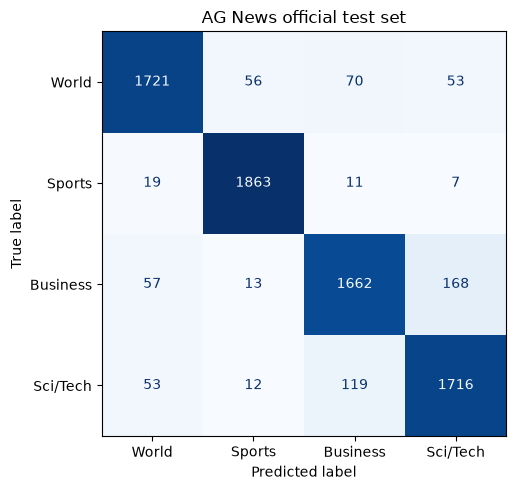

In [22]:
if TASK3_MODE == "final":
    topic_ids = np.arange(len(class_names))
    task3_accuracy = float(np.mean(test_targets == test_predictions))
    task3_macro_f1 = metrics.f1_score(test_targets, test_predictions, labels=topic_ids, average="macro")
    print(metrics.classification_report(
        test_targets, test_predictions, labels=topic_ids, target_names=class_names,
        digits=4, zero_division=0,
    ))
    task3_confusion = metrics.confusion_matrix(test_targets, test_predictions, labels=topic_ids)
    constant_accuracy = task3_confusion.sum(axis=1).max() / len(test_targets)
    print(f"Correct: {np.trace(task3_confusion):,}/{len(test_targets):,} "
          f"({task3_accuracy:.2%}); macro-F1: {task3_macro_f1:.4f}.")
    print(f"Accuracy gain over the constant-topic baseline ({constant_accuracy:.0%}): "
          f"{100 * (task3_accuracy - constant_accuracy):.2f} percentage points.")

    # Confusion matrix; the diagonal counts correct predictions.
    _, matrix_ax = plt.subplots(figsize=(6, 5))
    metrics.ConfusionMatrixDisplay(task3_confusion, display_labels=class_names).plot(
        ax=matrix_ax, cmap="Blues", values_format="d", colorbar=False
    )
    matrix_ax.set_title("AG News official test set")
    plt.tight_layout()
    plt.show()

### Training curves

The lines follow the selected run, including the epochs observed while early stopping waited for validation loss to improve. The vertical mark identifies the epoch saved in the checkpoint.

For the 128-token run, training accuracy rose from 86.28% to 95.38% over three epochs. Validation accuracy peaked at 91.75% in epoch 1 and fell to 91.02% by epoch 3, while validation loss rose from 0.252 to 0.290. The later epochs fitted the training articles more closely. Early stopping kept the first checkpoint for evaluation.

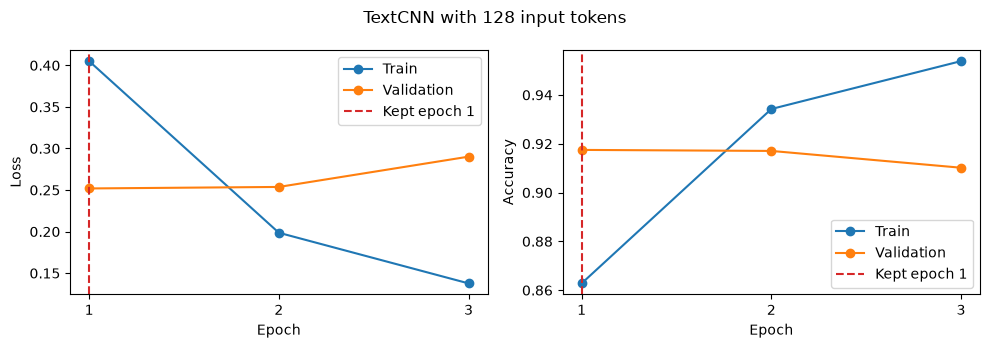

In [23]:
if TASK3_MODE == "final":
    task3_epochs = np.arange(1, len(selected_history["loss"]) + 1)
    curve_fig, curve_axes = plt.subplots(1, 2, figsize=(10, 3.5))
    for curve_ax, metric in zip(curve_axes, ("loss", "accuracy"), strict=True):
        curve_ax.plot(task3_epochs, selected_history[metric], "o-", label="Train")
        curve_ax.plot(task3_epochs, selected_history[f"val_{metric}"], "o-", label="Validation")
        curve_ax.axvline(
            selected_epoch, color="tab:red", linestyle="--", label=f"Kept epoch {selected_epoch}"
        )
        curve_ax.set(xlabel="Epoch", ylabel=metric.capitalize(), xticks=task3_epochs)
        curve_ax.legend()
    curve_fig.suptitle(f"TextCNN with {selected_length} input tokens")
    curve_fig.tight_layout()
    plt.show()

### Read a few predictions

We show the first correct article for each topic, then up to two early errors from each of the two most frequent directed confusions. Row IDs follow the fixed TFDS test order. The excerpt is taken from the words the model could see. The token counts give context for inspecting truncation and unknown words.

In [24]:
if TASK3_MODE == "final":
    # Find incorrect predictions. Break tied counts by topic ID for a repeatable sample.
    error_mask = test_predictions != test_targets
    error_total = int(error_mask.sum())
    topic_pairs = sorted(
        ((a, b) for a in topic_ids for b in topic_ids if a != b and task3_confusion[a, b]),
        key=lambda pair: (-int(task3_confusion[pair]), pair),
    )
    example_rows: list[int] = []
    for correct_topic in topic_ids:
        hits = np.flatnonzero((test_targets == correct_topic) & ~error_mask)
        example_rows.extend(hits[:1].tolist())

    print(f"Total errors: {error_total:,} / {len(test_targets):,}")
    clipped = np.asarray([len(text.split()) > selected_length for text in test_texts], dtype=bool)
    for group_name, members in (("Fits input", ~clipped), ("Truncated", clipped)):
        total = int(members.sum())
        if total:
            misses = int(error_mask[members].sum())
            print(f"{group_name}: {misses}/{total} errors ({misses / total:.1%})")
    for actual_topic, assigned_topic in topic_pairs[:2]:
        hits = np.flatnonzero((test_targets == actual_topic) & (test_predictions == assigned_topic))
        print(f"{class_names[actual_topic]} → {class_names[assigned_topic]}: "
              f"{len(hits)} articles ({len(hits) / error_total:.1%} of all errors)")
        example_rows.extend(hits[:2].tolist())

    known_words = set(selected_vectorizer.get_vocabulary()[2:])
    for row_index in example_rows:
        words = test_texts[row_index].split()
        visible_words = words[:selected_length]
        unknown = sum(word not in known_words for word in visible_words)
        excerpt = " ".join(visible_words[:18]) + (" …" if len(visible_words) > 18 else "")
        print(f"test_{row_index:06d}  {class_names[test_targets[row_index]]} → "
              f"{class_names[test_predictions[row_index]]}  "
              f"({len(words)} words, {len(words) - len(visible_words)} cut, {unknown} unknown)")
        print(f"  {excerpt}")

Total errors: 638 / 7,600
Fits input: 636/7593 errors (8.4%)
Truncated: 2/7 errors (28.6%)
Business → Sci/Tech: 168 articles (26.3% of all errors)
Sci/Tech → Business: 119 articles (18.7% of all errors)
test_000001  World → World  (41 words, 0 cut, 1 unknown)
  philippine rebels free troops talks in doubt presentacion philippines reuters philippine communist rebels freed wednesday two soldiers they …
test_000000  Sports → Sports  (32 words, 0 cut, 0 unknown)
  carolina s davis done for the season charlotte n c sports network carolina panthers running back stephen davis …
test_000009  Business → Business  (31 words, 0 cut, 0 unknown)
  ford gm report slow november sales the nation s two largest automakers on wednesday reported weak november sales …
test_000002  Sci/Tech → Sci/Tech  (47 words, 0 cut, 3 unknown)
  new rainbow six franchise for spring 2005 san francisco ca november 30 2004 ubisoft one of the world …
test_000018  Business → Sci/Tech  (43 words, 0 cut, 2 unknown)
  peoplesof

### What the test errors tell us

The selected model classified **6,962 of 7,600** official test articles correctly (**91.61% accuracy**, **0.9159 macro-F1**). Each topic has 1,900 test articles. Sports had the highest F1 (0.9693) and Business the lowest (0.8836). Of the 638 mistakes, **287 (45.0%)** crossed the Business–Sci/Tech boundary: 168 Business articles went to Sci/Tech and 119 went the other way.

The iPod feature story (`test_000100`) is labelled Business and was predicted as Sci/Tech. The industrial robot sales story (`test_000024`) went the other way. The model saw every word in both articles and knew every word in the robot story. Product features and sales figures give these articles plausible cues for both topics. A CNN that retains the strongest local phrase response can lose the broader editorial angle.

Only seven test articles exceeded 128 tokens, and two of them were misclassified. The remaining 636 errors occurred on articles that fit in full. The four labels and historical English news sources also limit what this score can tell us about current or multilingual news. Grouping exact normalised texts still allows differently worded reports of the same event across partitions.

### Where to go next

Keep the 128-token checkpoint as the four-topic baseline. For the next experiment, sample Business–Sci/Tech mistakes from **validation** and mark whether the headline and description emphasise the same topic. That would help us decide whether to represent the headline separately or try an encoder that retains more sentence context. A follow-up on names could compare subword tokenisation with the current unknown-word token on the same validation articles. The seven truncated test articles give little evidence for increasing the length again.

## Conclusion

Summarise the findings and trade-offs after all experiments have been completed.

## References

- Huyen, C. (2022). *Designing Machine Learning Systems*. O’Reilly, chapters 4–6.
- [Keras transfer learning and fine-tuning](https://keras.io/guides/transfer_learning/).
- Howard et al. (2017). [MobileNets](https://arxiv.org/abs/1704.04861).
- Tan and Le (2021). [EfficientNetV2](https://proceedings.mlr.press/v139/tan21a.html).
- [TensorFlow Datasets: AG News](https://www.tensorflow.org/datasets/catalog/ag_news_subset).
- Zhang et al. (2015). [Character-level Convolutional Networks for Text Classification](https://arxiv.org/abs/1509.01626).
- Kim (2014). [Convolutional Neural Networks for Sentence Classification](https://aclanthology.org/D14-1181/).